# Supplementary Lecture: Quantum-Technology Roadmaps and AI Workflows

[Course contents](../00_course_contents.md) | [← Previous lecture](./12_superconducting_qubits.ipynb)

> **Open course material.** This notebook may be downloaded, taught, adapted, and shared with attribution. It supports institutional teaching, independent study, examination review, and preparation for quantum-technology roles. See the [reuse terms](../LICENSE), [teaching and self-study guide](../TEACHING_AND_SELF_STUDY.md), and [citation metadata](../CITATION.cff).

This supplementary lecture combines the book's appendices on modern quantum-technology roadmaps and the intersection of machine learning with quantum engineering.

## Learning objectives

- Evaluate quantum-technology claims using explicit units, baselines, uncertainty, and system-level metrics.
- Use simplified reliability, logical-error, and sensing models without confusing them with full device simulations.
- Distinguish AI as an engineering workbench, AI for quantum systems, and quantum methods for machine learning.
- Design verification gates for software, experimental control, learned models, and hybrid quantum-classical workflows.

## Core ideas

- **Metrics belong to layers.** Physical qubits, logical qubits, gate errors, circuit depth, sensitivity, and application performance are not interchangeable.
- **A roadmap is a dated target.** It is evidence of technical direction, not evidence that the target system has been delivered.
- **Suggestions are not measurements.** Models and software tools can accelerate iteration, but physical equations, tests, data, uncertainty, and strong baselines determine whether a result is credible.


## Software environment

The course uses the pinned packages in [`requirements.txt`](../requirements.txt). If they are not installed in the active Jupyter kernel, run:

```python
%pip install -r ../requirements.txt
```

Restart the kernel after installation. The next cell contains every library import required by this lecture; the notebook does not depend on variables or imports created by another lecture.

In [1]:
# Complete imports for this lecture.
from math import exp, log, sqrt
import numpy as np

## Why the field is at a systems-engineering inflection point

The engineering objective has shifted from demonstrating isolated qubits to sustaining useful logical operations. A fault-tolerant system must coordinate physical qubits, repeated syndrome measurements, classical decoding, feedforward, control electronics, calibration, packaging, cryogenics or optics, and application software.

Raw physical-qubit count remains useful, but it cannot answer the central questions:

- How many logical qubits are available at the required logical error rate?
- Which logical operations are supported, and at what space-time cost?
- How long can the computation run before its total failure probability becomes unacceptable?
- Which classical resources are required for compilation, decoding, calibration, and analysis?
- Does the complete workflow outperform the best relevant classical alternative?

Quantum sensing often reaches deployment with much smaller quantum systems because its target is parameter estimation rather than a long universal circuit. The challenge is then calibrated phase response, bandwidth, dynamic range, stability, traceability, and uncertainty—not billions of sequential logical gates.


## Read every metric at the correct layer

| Metric | What it measures | What it can conceal |
|---|---|---|
| **Physical qubits** | Fabricated device-level quantum elements | Error rates, leakage, yield, connectivity, calibration load, and usable depth |
| **Logical qubits** | Encoded quantum information protected by an error-correcting scheme | Physical overhead, decoder latency, logical gate set, and logical error per operation |
| **Gate fidelity or error** | Agreement with an ideal operation under a stated benchmark model | Correlated noise, drift, crosstalk, leakage, and mismatch with the target workload |
| **Coherence time** | Characteristic energy-relaxation or phase-memory time | Gate duration, measurement latency, duty cycle, and nonstationary noise |
| **Circuit depth or operations** | A workload-size measure under specified assumptions | Routing, parallelism, compiler choices, repetitions, and error-correction cycles |
| **Sensor sensitivity** | Noise-equivalent parameter resolution per square-root bandwidth | Dynamic range, dead time, calibration stability, spatial resolution, and environmental robustness |
| **Application score** | Performance on a selected benchmark or task | Data-loading cost, tuning effort, uncertainty, generalization, and strength of the classical baseline |

Vendor-defined aggregate metrics can be useful within a documented methodology, but they should not be compared across platforms as though they were universal physical units.


## A first reliability estimate

Assume $G$ operations, each with an identical independent failure probability $p_g$. The probability of no failures is

$$
P_{\mathrm{success}}=(1-p_g)^G.
$$

For $p_g\ll1$,

$$
P_{\mathrm{success}}\approx e^{-G p_g}.
$$

The approximation provides intuition, not a hardware prediction. It omits correlated faults, leakage, drift, idling errors, measurement faults, compiler-dependent routing, and recovery. Solving the exact model for the largest allowable error at a target success probability $P_\star$ gives

$$
p_g\leq 1-P_\star^{1/G}.
$$


In [2]:
def exact_success_probability(operations: int, error_per_operation: float) -> float:
    if operations < 0 or not 0 <= error_per_operation <= 1:
        raise ValueError("Use operations >= 0 and 0 <= error_per_operation <= 1.")
    return (1.0 - error_per_operation) ** operations


def exponential_approximation(operations: int, error_per_operation: float) -> float:
    return exp(-operations * error_per_operation)


def maximum_error_for_target(operations: int, target_success: float) -> float:
    if operations <= 0 or not 0 < target_success <= 1:
        raise ValueError("Use operations > 0 and 0 < target_success <= 1.")
    return 1.0 - target_success ** (1.0 / operations)


print(f"{'G':>10} {'p_g':>10} {'exact':>14} {'exp(-G p_g)':>14}")
for operations in (1_000, 1_000_000):
    for error in (1e-2, 1e-3, 1e-4):
        exact = exact_success_probability(operations, error)
        approx = exponential_approximation(operations, error)
        print(f"{operations:10,d} {error:10.0e} {exact:14.3e} {approx:14.3e}")

target = 0.50
operations = 250_000
limit = maximum_error_for_target(operations, target)
print(f"\nFor G={operations:,} and P_success >= {target:.2f}, p_g <= {limit:.3e}.")
print(f"Small-error estimate: {-log(target) / operations:.3e}.")

         G        p_g          exact    exp(-G p_g)
     1,000      1e-02      4.317e-05      4.540e-05
     1,000      1e-03      3.677e-01      3.679e-01
     1,000      1e-04      9.048e-01      9.048e-01
 1,000,000      1e-02      0.000e+00      0.000e+00
 1,000,000      1e-03      0.000e+00      0.000e+00
 1,000,000      1e-04      3.702e-44      3.720e-44

For G=250,000 and P_success >= 0.50, p_g <= 2.773e-06.
Small-error estimate: 2.773e-06.


## Error correction changes the scaling problem

A frequently used below-threshold heuristic is

$$
p_L\approx A\left(\frac{p}{p_{\mathrm{th}}}\right)^{(d+1)/2},
$$

where $p_L$ is a logical error probability per specified cycle or operation, $p$ is a physical error parameter, $p_{\mathrm{th}}$ is a model-dependent threshold, $d$ is code distance, and $A$ is a fitted prefactor.

This expression is not universal. The numerical values depend on the code, circuit, decoder, noise model, boundaries, leakage treatment, and definition of a cycle. Its essential lesson is conditional:

- if the effective physical noise is below threshold, increasing distance can suppress logical error;
- if it is above threshold, adding components can make performance worse;
- useful computation requires a logical error budget for the complete sequence, including logical gates, state preparation, measurement, memory, routing, and decoding latency.


In [3]:
def logical_error_heuristic(
    physical_error: float,
    threshold: float,
    distance: int,
    prefactor: float = 0.1,
) -> float:
    if not 0 < physical_error < threshold:
        raise ValueError("This below-threshold heuristic requires 0 < p < p_threshold.")
    if distance < 1 or distance % 2 == 0:
        raise ValueError("Use a positive odd code distance for this example.")
    return prefactor * (physical_error / threshold) ** ((distance + 1) / 2)


for distance in (3, 5, 7, 9):
    estimate = logical_error_heuristic(1e-3, 1e-2, distance)
    print(f"distance {distance:2d}: toy logical error = {estimate:.3e}")

assert logical_error_heuristic(1e-3, 1e-2, 9) < logical_error_heuristic(
    1e-3, 1e-2, 5
)

distance  3: toy logical error = 1.000e-03
distance  5: toy logical error = 1.000e-04
distance  7: toy logical error = 1.000e-05
distance  9: toy logical error = 1.000e-06


## Sensing claims require an uncertainty model

Let a measured observable $M$ depend on a parameter $x$. Near an operating point, error propagation for $N$ independent repetitions gives

$$
\delta x\approx
\frac{\sigma_M}{\sqrt{N}\left|\partial\langle M\rangle/\partial x\right|}.
$$

A steeper response, lower measurement noise, or more independent samples improves this bound. The $1/\sqrt N$ factor does not apply unchanged when samples are correlated. A real sensor report should also specify bandwidth, averaging time, dynamic range, spatial resolution, duty cycle, calibration uncertainty, and environmental conditions.


In [4]:
def parameter_resolution(
    measurement_std: float,
    response_slope: float,
    independent_repetitions: int = 1,
) -> float:
    if measurement_std < 0 or response_slope == 0 or independent_repetitions <= 0:
        raise ValueError("Check the standard deviation, slope, and repetition count.")
    return measurement_std / (
        sqrt(independent_repetitions) * abs(response_slope)
    )


for repetitions in (1, 100, 10_000):
    resolution = parameter_resolution(1.0, 250.0, repetitions)
    print(f"N={repetitions:6,d}: delta_x = {resolution:.3e}")

assert parameter_resolution(1.0, 250.0, 10_000) == parameter_resolution(
    1.0, 250.0, 1
) / 100

N=     1: delta_x = 4.000e-03
N=   100: delta_x = 4.000e-04
N=10,000: delta_x = 4.000e-05


## Platform families optimize different resources

| Platform | Typical encoding | Characteristic strengths | System bottlenecks |
|---|---|---|---|
| **Superconducting circuits** | Microwave excitations of Josephson circuits | Fast gates, lithographic fabrication, mature microwave-control ecosystem | Cryogenic wiring, crosstalk, materials loss, leakage, packaging, calibration |
| **Trapped ions** | Internal states of charged atoms | Long coherence, high-fidelity operations, strong connectivity within modules | Optical complexity, gate time, motional-mode control, module interconnects |
| **Neutral atoms** | Hyperfine or electronic states with Rydberg interactions | Large reconfigurable arrays and parallel operations | Loading defects, atom loss, laser stability, measurement and QEC cycle time |
| **Photonics** | Path, polarization, time-bin, frequency, or continuous-variable modes | Networking compatibility and room-temperature propagation | Source quality, optical loss, detector efficiency, switching, feedforward |
| **Semiconductor spins** | Electron or nuclear spin states | Compact footprint and possible semiconductor-process integration | Uniformity, yield, dense wiring, control crosstalk, readout fidelity |
| **Annealing systems** | Coupled analog variables | Large special-purpose optimization networks | Analog-control precision and limited comparability with universal gate-model computation |

No platform dominates every metric. Comparisons should hold the task, accuracy, workload definition, and reporting layer fixed.


## Classical engineering is inside the quantum computer

| Engineering layer | Why it matters | Representative work |
|---|---|---|
| RF, microwave, and optical control | Phase noise, distortion, timing, and amplitude errors change the implemented Hamiltonian | Sources, modulators, AWGs, DAC/ADC chains, pulse shaping, laser locking |
| Readout and detection | Quantum signals are weak and classification errors enter the algorithm | Amplification, impedance matching, photodetection, filtering, DSP, calibration |
| Packaging and thermal design | Scaling adds heat load, loss, crosstalk, alignment, and interconnect density | Cryogenic packaging, interposers, photonic packaging, shielding, thermal models |
| Control and calibration | Device parameters drift and large systems cannot be tuned manually | System identification, optimal control, automation, anomaly detection |
| Error-correction electronics | Syndromes must be decoded within the timing budget | FPGA/ASIC decoders, low-latency routing, synchronization, feedforward |
| Verification and software | A plausible output can still represent the wrong physical model | Unit tests, invariants, versioned workflows, benchmarks, uncertainty analysis |

Quantum engineering is hardware–software co-design. The classical subsystem is not ancillary overhead; it is part of the machine being evaluated.


## How to read a roadmap without turning it into a prediction

Use a six-part record:

1. **Date and source:** retain the official page or paper and the access date.
2. **Status:** label a result as demonstrated, announced, targeted, simulated, or projected.
3. **Unit:** distinguish physical qubits, logical qubits, modes, operations, cycles, and application scores.
4. **Conditions:** record the code, noise model, success criterion, accuracy, and workload.
5. **Dependencies:** identify fabrication, interconnect, control, decoding, software, and supply-chain assumptions.
6. **Evidence needed next:** state the experiment or benchmark that would reduce uncertainty.

### Two examples with different evidence status

- IBM's Technology Atlas, updated March 2026, **targets** a 2029 Starling system with 200 logical qubits and 100 million gates. The page explicitly identifies its statements as goals subject to change. This is a dated roadmap target, not a delivered system.
- Google's Willow work **demonstrated** below-threshold surface-code memories through increasing code distance. This is an important error-correction result, but it is not a demonstration of a complete general-purpose fault-tolerant computer.

Keeping *target* and *demonstration* separate prevents a roadmap from being mistaken for experimental evidence.


## Three distinct roles for AI in quantum engineering

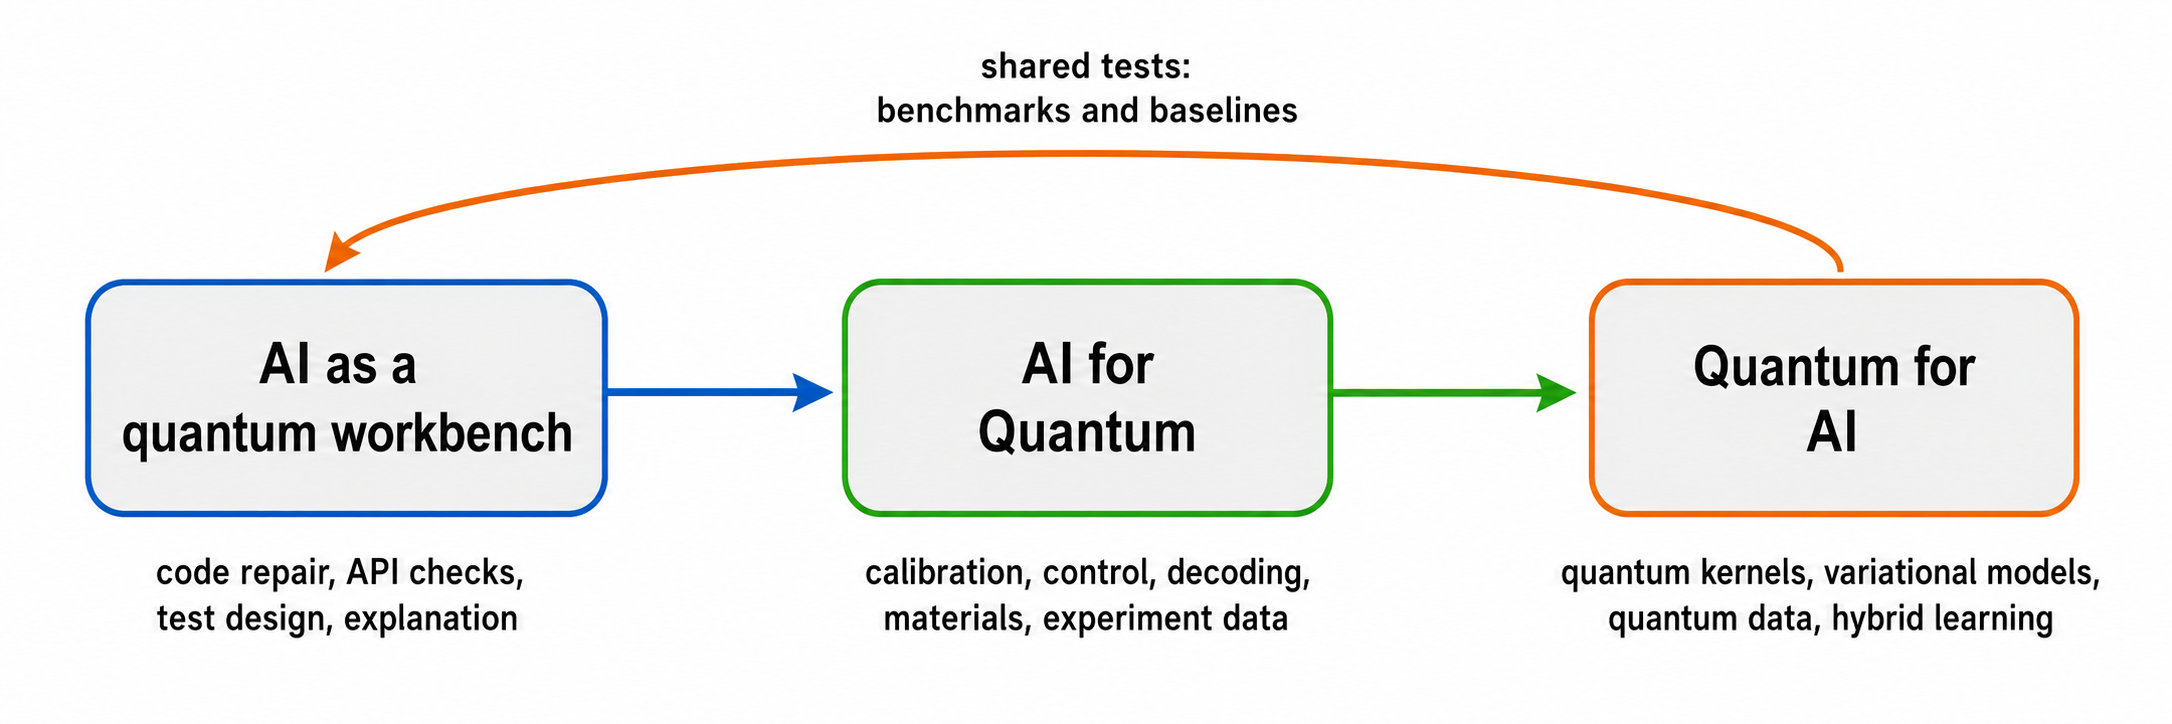

*The blue block represents AI tools used during coding, API checking, test design, and explanation. The green block represents machine-learning methods applied to calibration, control, decoding, materials, and experimental data. The orange block represents quantum kernels, variational models, quantum data, and other quantum components used in learning workflows. The return arrow emphasizes that all three roles require shared benchmarks, baselines, and reproducible tests; evidence in one category does not establish a claim in another.*


| Role | Typical use | Required evidence |
|---|---|---|
| **AI as a quantum workbench** | Code suggestions, debugging, test generation, API lookup, explanation | Executable code, official API sources, analytic limits, unit tests, and independent review |
| **AI for Quantum** | Calibration, control, decoding, noise inference, surrogate models, materials and experiment analysis | Measured improvement against a strong method, uncertainty, latency, robustness, and out-of-distribution tests |
| **Quantum for AI** | Quantum kernels, parameterized circuits, generative sampling, learning from quantum data | End-to-end comparison including encoding, shots, optimization, mitigation, runtime, and tuned classical baselines |

The term *AI in quantum* is too broad unless the role, data, action, and evidence standard are stated.


## A verification loop for computational and experimental work

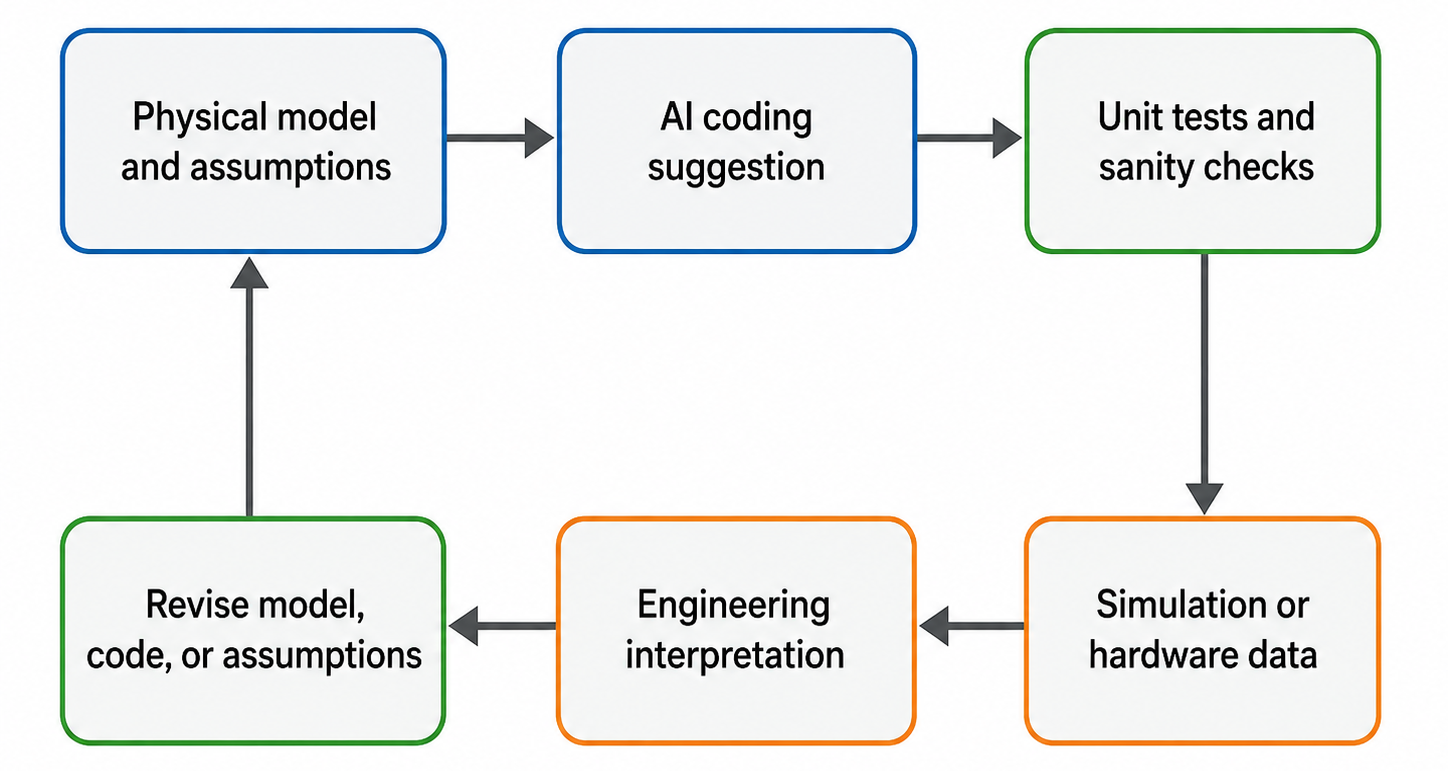

*The loop begins with explicit physical assumptions. A coding suggestion is admitted only after unit tests and sanity checks. Simulation or hardware data are interpreted in engineering terms, and discrepancies trigger revision of the model, code, or assumptions. The cycle keeps authority with reproducible physics and measured evidence rather than with the intermediate software tool.*


## Verification gates for quantum code

Before accepting a result, check the invariants appropriate to its representation:

- **Statevector:** shape $2^n$, finite complex entries, and $\langle\psi\vert\psi\rangle=1$.
- **Density operator:** $\rho=\rho^\dagger$, $\rho\succeq0$, and $\operatorname{Tr}(\rho)=1$.
- **Unitary:** $U^\dagger U=I$ within a documented tolerance.
- **Quantum channel:** dimensions are correct, the map is completely positive and trace preserving, and limiting cases agree with the model.
- **Circuit:** qubit order, measurement basis, classical registers, control/target order, parameters, and expected support are explicit.
- **Physical model:** units, sign conventions, Hamiltonian factors, rates, initial conditions, and truncation are documented.
- **Numerical result:** tolerances, random seeds, uncertainty, convergence, and a simple analytic or classical reference are retained.

A successful run only proves that the software executed. These checks address whether it executed the intended mathematics and physical model.


In [5]:
def audit_density_matrix(rho: np.ndarray, atol: float = 1e-12) -> dict[str, object]:
    rho = np.asarray(rho, dtype=complex)
    square = rho.ndim == 2 and rho.shape[0] == rho.shape[1]
    hermitian = square and np.allclose(rho, rho.conj().T, atol=atol)
    trace_one = square and np.isclose(np.trace(rho), 1.0, atol=atol)
    eigenvalues = np.linalg.eigvalsh(rho) if hermitian else None
    positive = bool(hermitian and np.all(eigenvalues >= -atol))
    return {
        "square": square,
        "Hermitian": hermitian,
        "trace_one": bool(trace_one),
        "positive_semidefinite": positive,
        "eigenvalues": eigenvalues,
        "physical_density_matrix": bool(square and hermitian and trace_one and positive),
    }


candidate = np.array([[0.7, 0.4], [0.1, 0.3]], dtype=complex)
audit = audit_density_matrix(candidate)
for key, value in audit.items():
    print(f"{key}: {value}")

assert audit["trace_one"]
assert not audit["Hermitian"]
assert not audit["physical_density_matrix"]

square: True
Hermitian: False
trace_one: True
positive_semidefinite: False
eigenvalues: None
physical_density_matrix: False


## AI for Quantum: measurable engineering objectives

Machine-learning models can be useful when a quantum apparatus produces high-dimensional, repeated telemetry:

- **calibration:** infer mappings between control settings and measured response;
- **control:** propose pulses or feedback policies under amplitude, bandwidth, leakage, and timing constraints;
- **decoding:** infer likely error histories from syndrome streams;
- **noise characterization:** identify drift, crosstalk, leakage, and temporal correlations;
- **surrogate modeling:** approximate an expensive simulator within a validated domain;
- **experiment design:** prioritize informative measurements or materials candidates.

The objective must be physical and testable: lower logical error, faster calibration, improved fidelity, lower estimation uncertainty, or increased robustness. Accuracy alone is insufficient when inference latency exceeds the control-cycle budget or when training data omit relevant faults.

AlphaQubit is an instructive decoder example: learned decoding improved accuracy on experimental and simulated surface-code data, while its authors also reported scaling and throughput challenges. The correct conclusion is that learned decoders are promising candidates to benchmark—not that all decoding has been solved.


## Safe control requires bounded authority

A model that recommends a plot style is low risk. A model that changes microwave pulses, laser power, bias voltages, or cryogenic operating parameters can alter hardware and invalidate calibration. Before closed-loop use, define:

1. permitted parameters and hard numerical bounds;
2. rate-of-change and cumulative-change limits;
3. a validated baseline controller;
4. a simulation or shadow-mode stage;
5. abort and rollback conditions;
6. independent monitoring channels;
7. an immutable log of inputs, proposed actions, accepted actions, and measured outcomes;
8. human authorization appropriate to the equipment risk.

Learning-based control should be evaluated for robustness to drift, missing sensors, distribution shift, adversarial or corrupted telemetry, and failure outside the training domain.


## Quantum for AI: kernels, variational models, and quantum data

A quantum feature map encodes an input $x$ as a state $\lvert\phi(x)\rangle$. One common kernel is

$$
K(x,x')=\left|\langle\phi(x)\vert\phi(x')\rangle\right|^2.
$$

The squared overlap is bounded between zero and one for normalized states. A quantum processor may estimate it with circuits and repeated measurements. A useful end-to-end claim must include:

- the cost of encoding classical data;
- circuit compilation, depth, and hardware errors;
- the shots needed for the required kernel precision;
- optimization and hyperparameter-search cost;
- error mitigation or correction overhead;
- a tuned classical kernel or model using the same train/test protocol.

Quantum-data settings can alter this accounting because the source is already a quantum state, but measurement access and copy complexity still matter.


In [6]:
def feature_state(x: float) -> np.ndarray:
    state = np.array([np.cos(x), np.sin(x)], dtype=complex)
    assert np.allclose(np.vdot(state, state), 1.0)
    return state


def state_overlap_kernel(x: float, x_prime: float) -> float:
    overlap = np.vdot(feature_state(x), feature_state(x_prime))
    return float(abs(overlap) ** 2)


x, x_prime = 0.2, 1.1
kernel = state_overlap_kernel(x, x_prime)
analytic = np.cos(x - x_prime) ** 2
print("kernel from states:", kernel)
print("analytic value:", analytic)

assert 0.0 <= kernel <= 1.0
assert np.allclose(kernel, analytic)

kernel from states: 0.3863989526534564
analytic value: 0.3863989526534564


## Variational models and trainability

Parameterized quantum circuits combine a quantum state preparation and measurement loop with a classical optimizer. They are flexible, but performance can be limited by:

- noisy objective estimates from finite shots and hardware error;
- optimizer cost that grows with parameter count;
- circuit depth and connectivity constraints;
- parameter-shift or other gradient-measurement overhead;
- **barren plateaus**, where gradients concentrate near zero and training becomes impractical;
- a classical model that reaches equal or better performance at lower cost.

Architecture, initialization, locality, cost-function choice, data encoding, and problem structure affect trainability. A high-dimensional Hilbert space is not useful merely because it is high dimensional; the relevant features must be accessible with efficient preparation, transformations, and measurements.


## Baselines and uncertainty decide whether an improvement is clear

For a hybrid score $P_q$ and a classical score $P_c$, define

$$
\Delta P=P_q-P_c.
$$

If independent standard uncertainties are $u_q$ and $u_c$, the uncertainty of the difference is

$$
u_{\Delta}=\sqrt{u_q^2+u_c^2}.
$$

A positive point estimate does not establish a reliable improvement when $\Delta P$ is small compared with $u_\Delta$. Statistical significance is also not enough: practical relevance requires runtime, energy, data, tuning, hardware access, and reproducibility to be reported.


In [7]:
hybrid_score, hybrid_uncertainty = 92.0, 1.5
classical_score, classical_uncertainty = 91.2, 0.4

difference = hybrid_score - classical_score
combined_uncertainty = np.hypot(hybrid_uncertainty, classical_uncertainty)
standardized_difference = difference / combined_uncertainty

print(f"score difference = {difference:.2f} percentage points")
print(f"combined standard uncertainty = {combined_uncertainty:.2f} points")
print(f"difference / uncertainty = {standardized_difference:.2f}")

assert standardized_difference < 1.0

score difference = 0.80 percentage points
combined standard uncertainty = 1.55 points
difference / uncertainty = 0.52


## Where the directions meet: the measurement and control chain

A quantum processor or sensor sits inside a mixed classical–quantum system:

$$
\text{physical system}
\rightarrow\text{transduction and readout}
\rightarrow\text{digitization}
\rightarrow\text{inference}
\rightarrow\text{decision}
\rightarrow\text{control action}.
$$

Machine learning may act before an experiment by selecting parameters, during an experiment by decoding or adapting controls, after an experiment by fitting models, or during software development by proposing tests and code changes. At every location, record:

- what data enter the model;
- what action or conclusion it is allowed to produce;
- the physical and numerical constraints;
- the baseline and acceptance criterion;
- uncertainty and out-of-domain behavior;
- the permanent provenance record needed to reproduce the decision.

The higher the authority over equipment or scientific conclusions, the stronger the validation and oversight must be.


## Professional preparation

Quantum systems need engineers who combine one strong classical specialty with enough quantum mechanics to work correctly at the interface. Valuable combinations include:

- RF/microwave engineering with Hamiltonian control and qubit readout;
- photonics with sources, detectors, loss budgets, and quantum networking;
- FPGA/ASIC design with real-time decoding and feedforward;
- control theory with calibration, system identification, and robust optimization;
- cryogenic and packaging engineering with thermal, electromagnetic, and interconnect design;
- numerical computing with open-system models, uncertainty, testing, and reproducible workflows;
- machine learning with experiment design, telemetry, strong baselines, and safe deployment.

Career preparation should produce evidence: tested notebooks, clear assumptions, versioned environments, benchmark comparisons, uncertainty analysis, and concise explanations connecting data to physics.


## Review and extension problems

1. A circuit contains $G=250{,}000$ independent operations. Derive the maximum $p_g$ compatible with $P_{\mathrm{success}}\geq0.5$ using the exact formula and compare it with $-\ln(0.5)/G$.
2. Evaluate the toy logical-error heuristic at $p=10^{-3}$, $p_{\mathrm{th}}=10^{-2}$, $A=0.1$, and distances $d=5$ and $d=9$. List four reasons the numbers are not device predictions.
3. A sensor has $\sigma_M=0.8$ and $|\partial\langle M\rangle/\partial x|=150$. Find the single-shot resolution and the independent sample count required for $\delta x<10^{-4}$.
4. Audit $\rho=\begin{bmatrix}0.7&0.4\\0.1&0.3\end{bmatrix}$. Identify each density-operator condition that passes or fails.
5. A hybrid model reports $92.0\%\pm1.5\%$ and a classical baseline reports $91.2\%\pm0.4\%$. Explain why the result does not establish a clear advantage, then list the end-to-end costs still missing.
6. Design a safe validation plan for a learned controller that proposes microwave-pulse changes. Include bounds, shadow-mode testing, rollback, monitoring, logging, and a baseline.
7. Select one current public quantum roadmap. Create a one-page record containing date, status, metric definitions, dependencies, evidence already demonstrated, and the next falsifiable milestone.


## Key takeaways

- Evaluate logical performance, error budgets, latency, and application cost—not physical-qubit count alone.
- Use reliability and logical-error formulas as explicit conditional models, never as substitutes for device data.
- Separate demonstrated results from dated roadmap targets.
- Distinguish AI workbench tools, AI for Quantum, and Quantum for AI; each requires a different baseline and evidence standard.
- Validate quantum code with mathematical invariants, units, limiting cases, and independent calculations.
- Give learned controllers bounded authority, rollback rules, monitoring, and complete logs.
- Judge hybrid learning claims end to end, including data encoding, shots, optimization, mitigation, uncertainty, and strong classical baselines.


## References and further reading

**Course-wide reference**

A. Krasnok, [*Introduction to Quantum Computing and Sensing for Electrical Engineers: A Hands-On Guide*](https://link.springer.com/book/9783032345295), *Synthesis Lectures on Emerging Engineering Technologies*, Springer, Cham, 1st ed., forthcoming September 2026, 403 pp. Hardcover ISBN 978-3-032-34529-5; eBook ISBN 978-3-032-34530-1.

1. J. Preskill, [“Quantum Computing in the NISQ Era and Beyond,”](https://quantum-journal.org/papers/q-2018-08-06-79/) *Quantum* **2**, 79 (2018).
2. IBM, [Quantum Technology Atlas: 2030 roadmap](https://www.ibm.com/roadmaps/quantum/2030/), updated March 2026. Roadmap values are stated goals subject to change.
3. Google Quantum AI and Collaborators, [“Quantum Error Correction Below the Surface Code Threshold,”](https://doi.org/10.1038/s41586-024-08449-y) *Nature* **638**, 920–926 (2025), with the linked 2026 correction.
4. C. L. Degen, F. Reinhard, and P. Cappellaro, [“Quantum Sensing,”](https://doi.org/10.1103/RevModPhys.89.035002) *Reviews of Modern Physics* **89**, 035002 (2017).
5. E. Tabassi, [*Artificial Intelligence Risk Management Framework (AI RMF 1.0)*](https://doi.org/10.6028/NIST.AI.100-1), NIST AI 100-1 (2023).
6. G. Carleo et al., [“Machine Learning and the Physical Sciences,”](https://doi.org/10.1103/RevModPhys.91.045002) *Reviews of Modern Physics* **91**, 045002 (2019).
7. J. Bausch et al., [“Learning High-Accuracy Error Decoding for Quantum Processors,”](https://doi.org/10.1038/s41586-024-08148-8) *Nature* **635**, 834–840 (2024).
8. M. Y. Niu et al., [“Universal Quantum Control through Deep Reinforcement Learning,”](https://doi.org/10.1038/s41534-019-0141-3) *npj Quantum Information* **5**, 33 (2019).
9. J. Biamonte et al., [“Quantum Machine Learning,”](https://doi.org/10.1038/nature23474) *Nature* **549**, 195–202 (2017).
10. M. Schuld and N. Killoran, [“Quantum Machine Learning in Feature Hilbert Spaces,”](https://doi.org/10.1103/PhysRevLett.122.040504) *Physical Review Letters* **122**, 040504 (2019).
11. V. Havlíček et al., [“Supervised Learning with Quantum-Enhanced Feature Spaces,”](https://doi.org/10.1038/s41586-019-0980-2) *Nature* **567**, 209–212 (2019).
12. M. Cerezo et al., [“Variational Quantum Algorithms,”](https://doi.org/10.1038/s42254-021-00348-9) *Nature Reviews Physics* **3**, 625–644 (2021).
13. J. R. McClean et al., [“Barren Plateaus in Quantum Neural Network Training Landscapes,”](https://doi.org/10.1038/s41467-018-07090-4) *Nature Communications* **9**, 4812 (2018).
